# 1. Import libraries 

In [2]:
import tensorflow as tf 
from tensorflow.keras.models import Sequential 
from tensorflow.keras.layers import Conv2D, MaxPooling2D, Flatten, Dense, Activation, Dropout, BatchNormalization
from tensorflow.keras.datasets import mnist
from tensorflow.keras.utils import to_categorical
import matplotlib.pyplot as plt 
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
import numpy as np

I0000 00:00:1779527218.381158   28437 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.
I0000 00:00:1779527220.894563   28437 cpu_feature_guard.cc:227] This TensorFlow binary is optimized to use available CPU instructions in performance-critical operations.
To enable the following instructions: AVX2 AVX_VNNI FMA, in other operations, rebuild TensorFlow with the appropriate compiler flags.
I0000 00:00:1779527262.117874   28437 port.cc:153] oneDNN custom operations are on. You may see slightly different numerical results due to floating-point round-off errors from different computation orders. To turn them off, set the environment variable `TF_ENABLE_ONEDNN_OPTS=0`.


In [3]:
print(tf.config.list_physical_devices('GPU'))

[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


# 2. Load the dataset 

In [4]:
(x_train, y_train), (x_test, y_test) = mnist.load_data()

In [5]:
x_train.shape 

(60000, 28, 28)

In [6]:
y_train.shape

(60000,)

# 3. Preprocessing and normalizing the data

In [7]:
rows, cols = 28, 28 
x_train = x_train.reshape(x_train.shape[0], rows, cols, 1)
x_test = x_test.reshape(x_test.shape[0], rows, cols, 1)
input_shape = (rows, cols, 1)
x_train = x_train.astype('float32') / 255.0
x_test = x_test.astype('float32') / 255.0
y_train = to_categorical(y_train, num_classes=10)
y_test = to_categorical(y_test, num_classes=10)

In [8]:
y_train.shape

(60000, 10)

In [9]:
y_test.shape

(10000, 10)

In [10]:
class_names = ['0','1','2','3','4','5','6','7','8','9']
num_classes = len(class_names)

In [11]:
np.argmax(y_train[5])

np.int64(2)

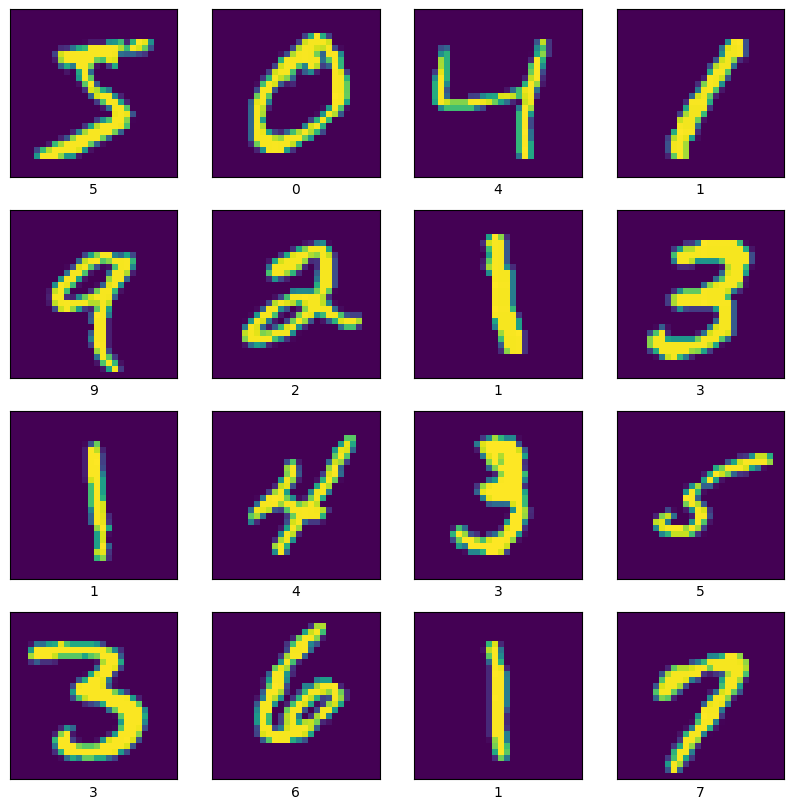

In [12]:
plt.figure(figsize=(10,10))
for i in range(16):
    plt.subplot(4,4,i+1)
    plt.xticks([])
    plt.yticks([])
    plt.grid(False)
    plt.imshow(x_train[i])
    plt.xlabel(class_names[np.argmax(y_train[i])])
plt.show()

# 4. Define the AlexNet model

In [13]:
model = Sequential()

# Layer 1 
model.add(Conv2D(96, kernel_size=(3,3), strides=(1,1), input_shape=input_shape, padding='same'))
model.add(Activation('relu')) 
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(BatchNormalization())
# Layer 2 
model.add(Conv2D(256, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))
model.add(BatchNormalization())
# Layer 3
model.add(Conv2D(384, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))

#layer 4 
model.add(Conv2D(384, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))

# Layer 5 
model.add(Conv2D(256, kernel_size=(3,3), strides=(1,1), padding='same'))
model.add(Activation('relu'))  
model.add(MaxPooling2D(pool_size=(2,2), strides=(2,2)))

# Flatten 
model.add(Flatten())

# Fully connected layer 1
model.add(Dense(1024))
model.add(Activation('relu'))
model.add(Dropout(0.5))

# Fully Connected Layer 2 
model.add(Dense(512))
model.add(Activation('relu'))
model.add(Dropout(0.5))

#Output layer 
model.add(Dense(10))
model.add(Activation('softmax'))

/mnt/d/Github/deep-learning-for-computer-vision/.venv/lib/python3.12/site-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)
I0000 00:00:1779527289.467178   28437 gpu_device.cc:2043] Created device /job:localhost/replica:0/task:0/device:GPU:0 with 1765 MB memory:  -> device: 0, name: NVIDIA GeForce RTX 2050, pci bus id: 0000:01:00.0, compute capability: 8.6


In [14]:
model.compile(loss='categorical_crossentropy',
              optimizer='adam',
              metrics=['accuracy'])

In [15]:
history = model.fit(x_train, y_train,
                    batch_size=128,
                    epochs=20,
                    validation_split=0.2,
                    verbose=2)

Epoch 1/20


I0000 00:00:1779527293.213234   30032 service.cc:153] XLA service 0x72d2a000a070 initialized for platform CUDA (this does not guarantee that XLA will be used). Devices:
I0000 00:00:1779527293.213265   30032 service.cc:161]   StreamExecutor [0]: NVIDIA GeForce RTX 2050, Compute Capability 8.6 (Driver: 13.0.0; Runtime: 12.5.0; Toolkit: 12.5.0; DNN: 9.21.1)
I0000 00:00:1779527293.351273   30032 dump_mlir_util.cc:269] disabling MLIR crash reproducer, set env var `MLIR_CRASH_REPRODUCER_DIRECTORY` to enable.
I0000 00:00:1779527293.948166   30032 cuda_dnn.cc:461] Loaded cuDNN version 92101
I0000 00:00:1779527294.051691   30032 dot_merger.cc:481] Merging Dots in computation: a_inference_one_step_on_data_3907__.56
I0000 00:00:1779527296.871284   30129 subprocess_compilation.cc:348] ptxas warning : Registers are spilled to local memory in function 'gemm_fusion_MatMul_14', 892 bytes spill stores, 892 bytes spill loads

I0000 00:00:1779527298.669650   30136 subprocess_compilation.cc:348] ptxas war

375/375 - 51s - 137ms/step - accuracy: 0.9159 - loss: 0.2702 - val_accuracy: 0.4033 - val_loss: 1.5562
Epoch 2/20
375/375 - 23s - 61ms/step - accuracy: 0.9800 - loss: 0.0714 - val_accuracy: 0.9860 - val_loss: 0.0532
Epoch 3/20
375/375 - 23s - 61ms/step - accuracy: 0.9851 - loss: 0.0558 - val_accuracy: 0.9882 - val_loss: 0.0446
Epoch 4/20
375/375 - 20s - 52ms/step - accuracy: 0.9886 - loss: 0.0429 - val_accuracy: 0.9782 - val_loss: 0.0840
Epoch 5/20
375/375 - 22s - 58ms/step - accuracy: 0.9897 - loss: 0.0394 - val_accuracy: 0.9870 - val_loss: 0.0487
Epoch 6/20
375/375 - 20s - 52ms/step - accuracy: 0.9910 - loss: 0.0359 - val_accuracy: 0.9872 - val_loss: 0.0465
Epoch 7/20
375/375 - 23s - 60ms/step - accuracy: 0.9910 - loss: 0.0345 - val_accuracy: 0.9892 - val_loss: 0.0478
Epoch 8/20
375/375 - 23s - 61ms/step - accuracy: 0.9928 - loss: 0.0269 - val_accuracy: 0.9887 - val_loss: 0.0611
Epoch 9/20
375/375 - 20s - 53ms/step - accuracy: 0.9924 - loss: 0.0327 - val_accuracy: 0.9806 - val_loss: 

In [16]:
loss, accuracy = model.evaluate(x_test, y_test, verbose=0)
print(f'Test loss: {loss:.4f}')
print(f'Test accuracy: {accuracy:.4f}')

Test loss: 0.0954
Test accuracy: 0.9873


# 5. Visualize result and refine model

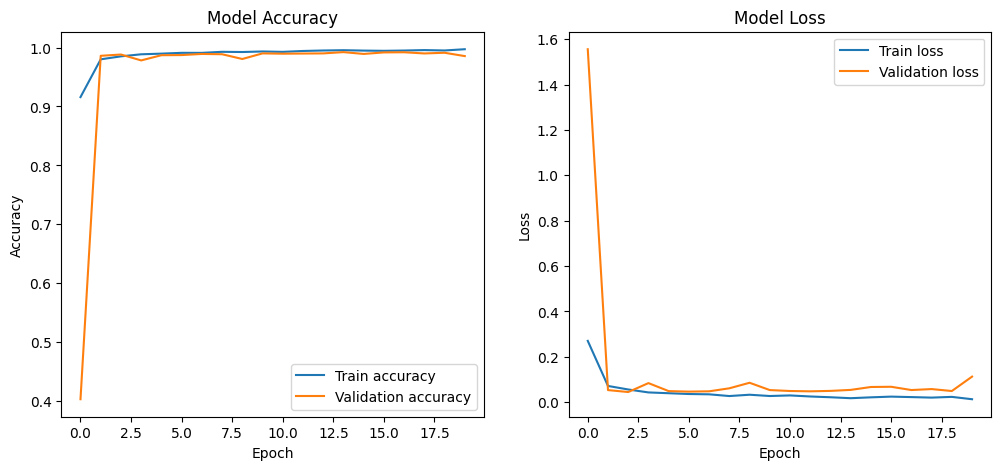

In [17]:
plt.figure(figsize=(12,5))
plt.subplot(1,2,1) 
plt.plot(history.history['accuracy'], label='Train accuracy')
plt.plot(history.history['val_accuracy'], label='Validation accuracy')
plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.legend()

plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train loss')
plt.plot(history.history['val_loss'], label='Validation loss')
plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')
plt.legend()
plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 2s 2s/step


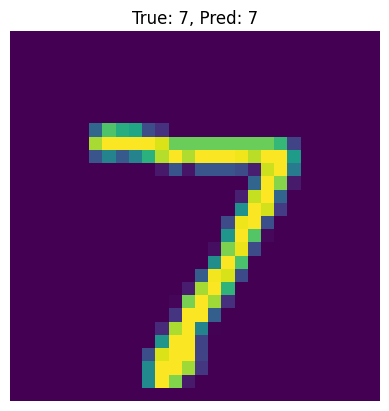

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


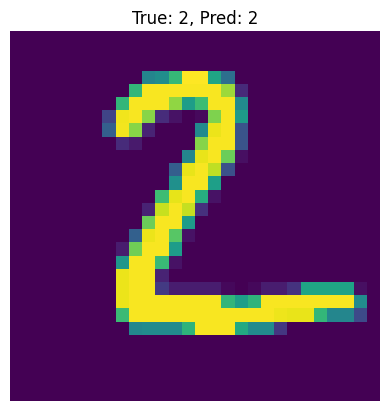

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 33ms/step


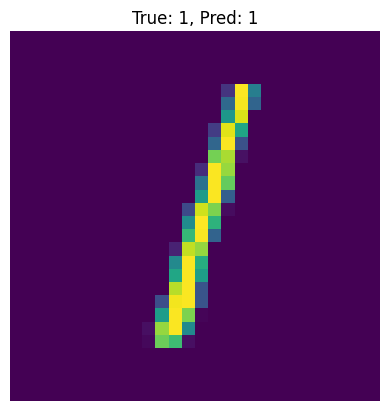

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


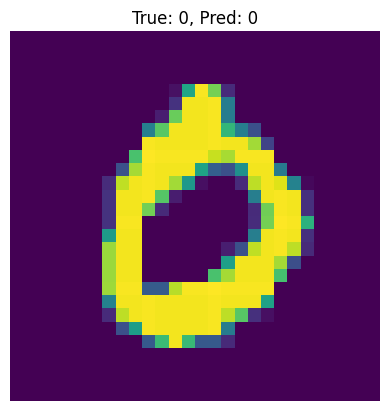

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


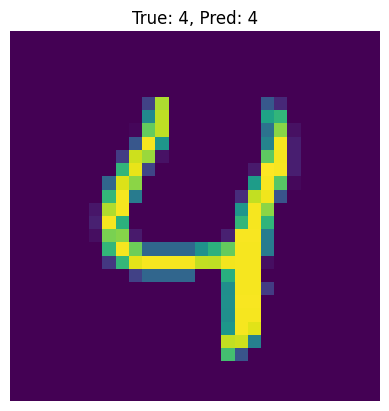

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


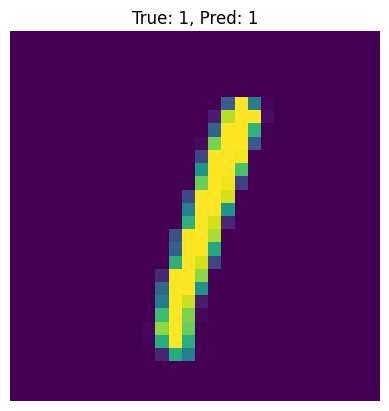

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 29ms/step


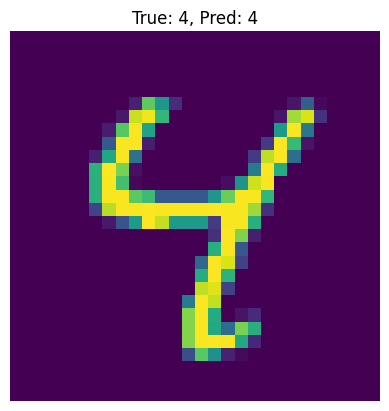

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 25ms/step


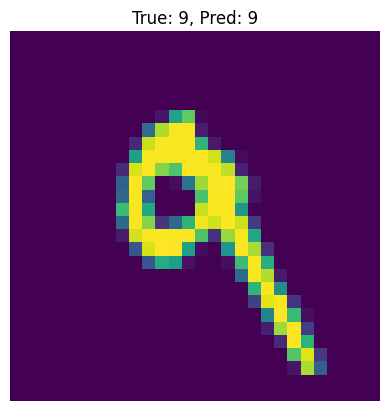

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 26ms/step


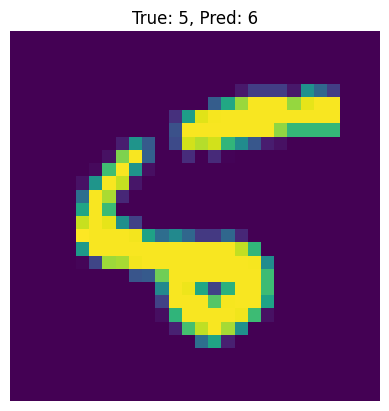

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


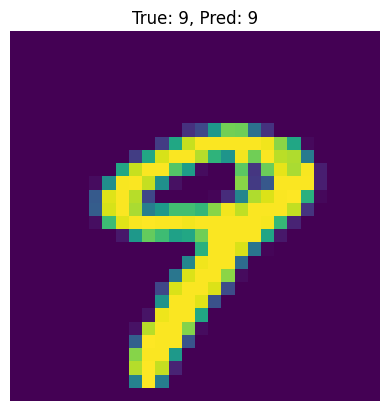

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


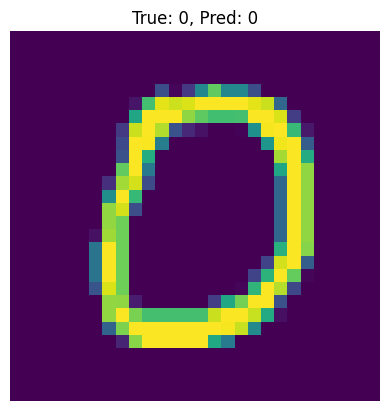

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 32ms/step


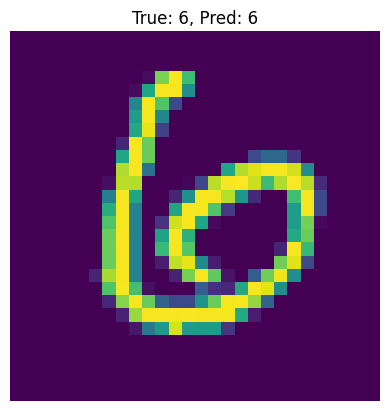

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


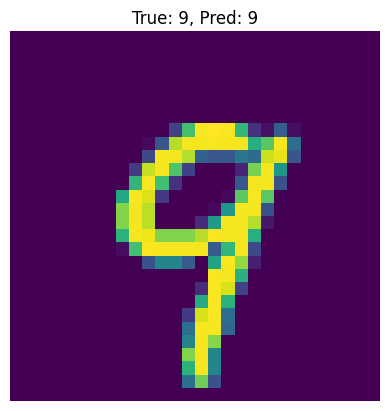

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 30ms/step


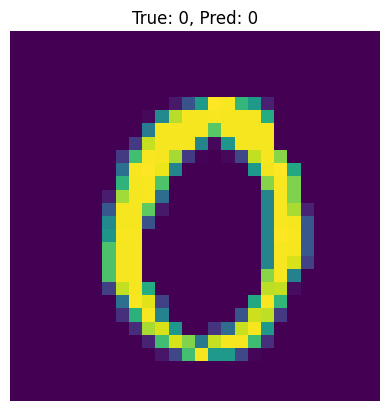

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 35ms/step


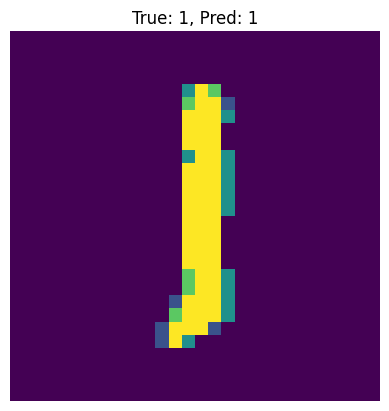

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 28ms/step


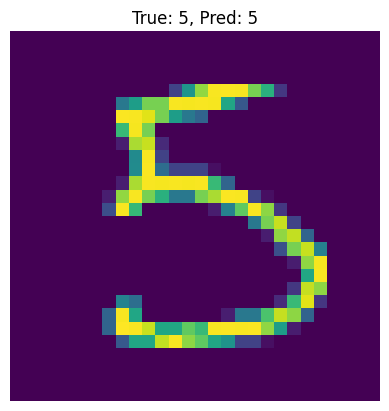

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 27ms/step


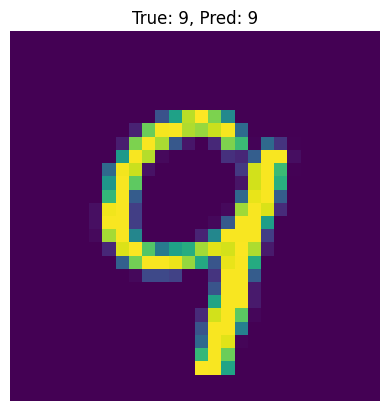

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


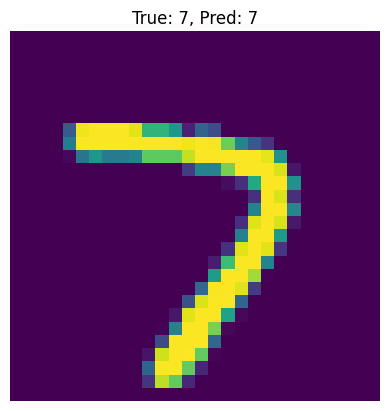

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 42ms/step


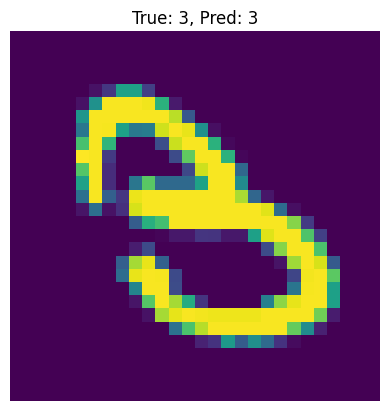

1/1 ━━━━━━━━━━━━━━━━━━━━ 0s 40ms/step


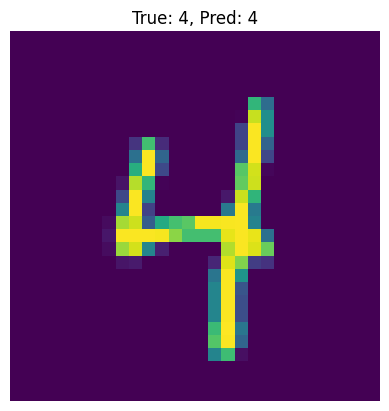

In [18]:
def plot_predictions(index): 
    img = x_test[index]
    true_label = class_names[np.argmax(y_test[index])]
    pred_probs = model.predict(np.expand_dims(img, axis=0))
    pred_label = class_names[np.argmax(pred_probs)]
    
    plt.imshow(img)
    plt.title(f'True: {true_label}, Pred: {pred_label}')
    plt.axis('off')
    plt.show()
for i in range(20):
    plot_predictions(i)

In [19]:
model.save('../data/models/alexnet_mnist.h5')